In [10]:
!pip -q install prophet

import pandas as pd
import numpy as np
import plotly.express as px
import matplotlib.pyplot as plt

In [11]:
url = "https://ws.cso.ie/public/api.restful/PxStat.Data.Cube_API.ReadDataset/HPM09/CSV/1.0/en"
df = pd.read_csv(url)
print(df.shape)
df.head()

(20800, 8)


,STATISTIC,Statistic Label,TLIST(M1),Month,C02803V03373,Type of Residential Property,UNIT,VALUE
0,HPM09C01,Residential Property Price Index,200501,2005 January,-,National - all residential properties,Base 2015=100,124.9
1,HPM09C01,Residential Property Price Index,200501,2005 January,01,National - houses,Base 2015=100,120.7
2,HPM09C01,Residential Property Price Index,200501,2005 January,02,National - apartments,Base 2015=100,153.4
3,HPM09C01,Residential Property Price Index,200501,2005 January,05,Dublin - all residential properties,Base 2015=100,118.5
4,HPM09C01,Residential Property Price Index,200501,2005 January,06,Dublin - houses,Base 2015=100,112.0


In [12]:
print(df["Statistic Label"].unique())
print(df["Type of Residential Property"].unique())
print(df["UNIT"].unique())
print(df.isna().sum())

['Residential Property Price Index'
 'Percentage Change over 1 month for Residential Property Price Index'
 'Percentage Change over 3 months for Residential Property Price Index'
 'Percentage Change over 12 months for Residential Property Price Index']
['National - all residential properties' 'National - houses'
 'National - apartments' 'Dublin - all residential properties'
 'Dublin - houses' 'Dublin - apartments' 'Dublin City - houses'
 'Dun Laoghaire-Rathdown - houses' 'Fingal - houses'
 'South Dublin - houses'
 'National excluding Dublin - all residential properties'
 'National excluding Dublin - houses'
 'National excluding Dublin - apartments' 'Border - houses'
 'Midland - houses' 'West - houses' 'Mid-East - houses'
 'Mid-West - houses' 'South-East - houses' 'South-West - houses']
['Base 2015=100' '%']
STATISTIC                          0
Statistic Label                    0
TLIST(M1)                          0
Month                              0
C02803V03373                     

In [13]:
stat_name = [s for s in df["Statistic Label"].unique() if "Index" in s][0]
prop_type = "National - all residential properties"

sub = df[(df["Statistic Label"] == stat_name) &
         (df["Type of Residential Property"] == prop_type)].copy()

sub["date"] = pd.to_datetime(sub["TLIST(M1)"].astype(str), format="%Y%m")
ts = sub.set_index("date")["VALUE"].sort_index()

print(ts.head())
print(ts.tail())
print("Months:", len(ts), "| Missing:", ts.isna().sum())

date
2005-01-01    124.9
2005-02-01    125.9
2005-03-01    126.6
2005-04-01    127.5
2005-05-01    128.4
Name: VALUE, dtype: float64
date
2026-04-01    205.0
2026-05-01    205.9
2026-06-01    207.0
2026-07-01    208.3
2026-08-01    209.7
Name: VALUE, dtype: float64
Months: 260 | Missing: 0


In [14]:
fig = px.line(ts, title="Residential Property Price Index (Ireland)",
              labels={"value": "Index", "date": ""})
fig.update_layout(showlegend=False)
fig.show()

In [15]:
test_size = 24
train, test = ts[:-test_size], ts[-test_size:]

# Naive baseline: repeat the last known value
naive_pred = pd.Series(train.iloc[-1], index=test.index)

def metrics(actual, pred):
    mae = np.mean(np.abs(actual - pred))
    rmse = np.sqrt(np.mean((actual - pred) ** 2))
    mape = np.mean(np.abs((actual - pred) / actual)) * 100
    return {"MAE": round(mae, 2), "RMSE": round(rmse, 2), "MAPE %": round(mape, 2)}

results = {"Naive": metrics(test, naive_pred)}
pd.DataFrame(results).T

,MAE,RMSE,MAPE %
Naive,13.31,14.98,6.58


Missing months: 0


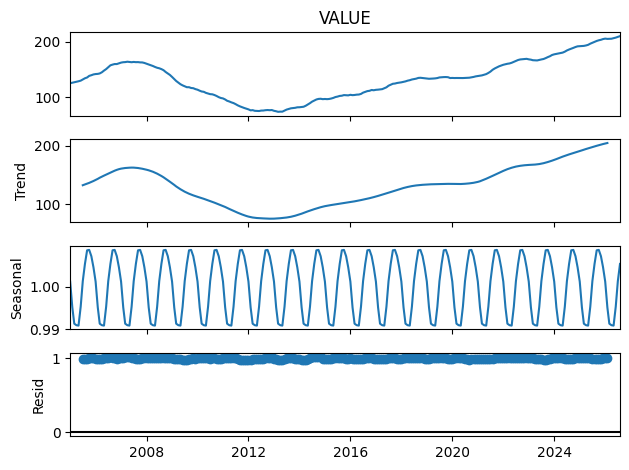

In [16]:
import warnings, itertools, logging
from statsmodels.tsa.statespace.sarimax import SARIMAX
from statsmodels.tsa.seasonal import seasonal_decompose

warnings.filterwarnings("ignore")
logging.getLogger("cmdstanpy").setLevel(logging.ERROR)
logging.getLogger("prophet").setLevel(logging.ERROR)

ts = ts.asfreq("MS")
print("Missing months:", ts.isna().sum())

test_size = 24
train, test = ts[:-test_size], ts[-test_size:]

dec = seasonal_decompose(ts, model="multiplicative", period=12)
dec.plot()
plt.show()

In [18]:
best = (None, np.inf)
for p, q, P, D, Q in itertools.product([0,1,2], [0,1,2], [0,1], [0,1], [0,1]):
    try:
        m = SARIMAX(train, order=(p,1,q), seasonal_order=(P,D,Q,12),
                    enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
        if m.aic < best[1]:
            best = ((p,1,q,P,D,Q), m.aic)
    except Exception:
        pass

print("Best settings (p,d,q,P,D,Q):", best[0], "| AIC:", round(best[1], 1))

Best settings (p,d,q,P,D,Q): (2, 1, 1, 0, 1, 1) | AIC: 413.0


In [19]:
order, sorder = best[0][:3], best[0][3:] + (12,)

sarima = SARIMAX(train, order=order, seasonal_order=sorder,
                 enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)

fc = sarima.get_forecast(steps=test_size)
sarima_pred = pd.Series(fc.predicted_mean.values, index=test.index)
sarima_ci = fc.conf_int()
sarima_ci.index = test.index

In [20]:
from prophet import Prophet

pdf = train.reset_index()
pdf.columns = ["ds", "y"]

prophet = Prophet(yearly_seasonality=True, weekly_seasonality=False,
                  daily_seasonality=False, interval_width=0.95)
prophet.fit(pdf)

future = prophet.make_future_dataframe(periods=test_size, freq="MS")
fc_p = prophet.predict(future).tail(test_size)
prophet_pred = pd.Series(fc_p["yhat"].values, index=test.index)

,MAE,RMSE,MAPE %
Naive,13.31,14.98,6.58
SARIMA,2.38,2.85,1.17
Prophet,1.95,2.11,0.98


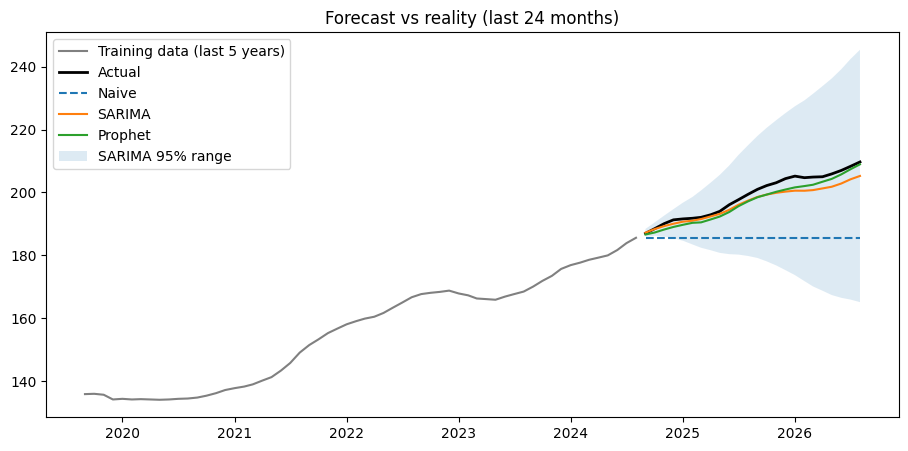

In [21]:
results = {
    "Naive":   metrics(test, naive_pred),
    "SARIMA":  metrics(test, sarima_pred),
    "Prophet": metrics(test, prophet_pred),
}
display(pd.DataFrame(results).T)

plt.figure(figsize=(11, 5))
plt.plot(train[-60:], label="Training data (last 5 years)", color="grey")
plt.plot(test, label="Actual", color="black", linewidth=2)
plt.plot(naive_pred, label="Naive", linestyle="--")
plt.plot(sarima_pred, label="SARIMA")
plt.plot(prophet_pred, label="Prophet")
plt.fill_between(test.index, sarima_ci.iloc[:, 0], sarima_ci.iloc[:, 1],
                 alpha=0.15, label="SARIMA 95% range")
plt.legend(); plt.title("Forecast vs reality (last 24 months)")
plt.show()

In [22]:
def backtest(fit_predict, ts, horizon=12, n_folds=4):
    rows = []
    for k in range(n_folds, 0, -1):
        cut = len(ts) - k * horizon
        tr, te = ts.iloc[:cut], ts.iloc[cut:cut + horizon]
        pred = fit_predict(tr, horizon, te.index)
        rows.append(metrics(te, pred))
    return pd.DataFrame(rows).mean().round(2)

def naive_fp(tr, h, idx):
    return pd.Series(tr.iloc[-1], index=idx)

def sarima_fp(tr, h, idx):
    m = SARIMAX(tr, order=order, seasonal_order=sorder,
                enforce_stationarity=False, enforce_invertibility=False).fit(disp=False)
    return pd.Series(m.forecast(h).values, index=idx)

def prophet_fp(tr, h, idx):
    d = tr.reset_index(); d.columns = ["ds", "y"]
    m = Prophet(yearly_seasonality=True, weekly_seasonality=False, daily_seasonality=False)
    m.fit(d)
    f = m.predict(m.make_future_dataframe(periods=h, freq="MS")).tail(h)
    return pd.Series(f["yhat"].values, index=idx)

bt = pd.DataFrame({
    "Naive":   backtest(naive_fp, ts),
    "SARIMA":  backtest(sarima_fp, ts),
    "Prophet": backtest(prophet_fp, ts),
}).T
display(bt)



,MAE,RMSE,MAPE %
Naive,5.83,6.43,3.08
SARIMA,3.72,4.25,2.09
Prophet,2.98,3.16,1.70


In [23]:
from xgboost import XGBRegressor

def drift_fp(tr, h, idx):
    slope = tr.diff().tail(12).mean()          # average monthly change, last 12 months
    return pd.Series(tr.iloc[-1] + slope * np.arange(1, h + 1), index=idx)

def seasonal_naive_fp(tr, h, idx):
    return pd.Series(tr.iloc[-12:].values[:h], index=idx)

def xgb_fp(tr, h, idx, n_lags=12):
    d = tr.diff().dropna()                      # monthly changes
    X = pd.DataFrame({f"lag{i}": d.shift(i) for i in range(1, n_lags + 1)})
    X["month"] = d.index.month
    data = pd.concat([X, d.rename("y")], axis=1).dropna()

    model = XGBRegressor(n_estimators=300, max_depth=3, learning_rate=0.05,
                         subsample=0.8, random_state=42)
    model.fit(data.drop(columns="y"), data["y"])

    hist, level, preds = list(d.values), tr.iloc[-1], []
    for date in idx:                            # forecast one month at a time
        row = {f"lag{i}": hist[-i] for i in range(1, n_lags + 1)}
        row["month"] = date.month
        step = model.predict(pd.DataFrame([row]))[0]
        level += step
        hist.append(step)
        preds.append(level)
    return pd.Series(preds, index=idx)

bt = pd.DataFrame({
    "Naive":          backtest(naive_fp, ts),
    "Naive + drift":  backtest(drift_fp, ts),
    "Seasonal naive": backtest(seasonal_naive_fp, ts),
    "SARIMA":         backtest(sarima_fp, ts),
    "Prophet":        backtest(prophet_fp, ts),
    "XGBoost":        backtest(xgb_fp, ts),
}).T
display(bt.sort_values("MAPE %"))



,MAE,RMSE,MAPE %
Prophet,2.98,3.16,1.70
SARIMA,3.72,4.25,2.09
XGBoost,4.32,4.86,2.44
Naive + drift,5.36,6.25,3.01
Naive,5.83,6.43,3.08
Seasonal naive,11.46,12.07,6.11


In [24]:
def ens_fp(tr, h, idx):
    return (prophet_fp(tr, h, idx) + sarima_fp(tr, h, idx)) / 2

def backtest_folds(fit_predict, ts, horizon=12, n_folds=8):
    rows = []
    for k in range(n_folds, 0, -1):
        cut = len(ts) - k * horizon
        tr, te = ts.iloc[:cut], ts.iloc[cut:cut + horizon]
        m = metrics(te, fit_predict(tr, horizon, te.index))
        m["test_start"] = te.index[0].strftime("%Y-%m")
        rows.append(m)
    return pd.DataFrame(rows)

models = {"Naive + drift": drift_fp, "SARIMA": sarima_fp,
          "Prophet": prophet_fp, "Prophet+SARIMA": ens_fp}
folds = {name: backtest_folds(fp, ts) for name, fp in models.items()}

mape_by_fold = pd.DataFrame({n: f["MAPE %"].values for n, f in folds.items()},
                            index=folds["Prophet"]["test_start"])
display(mape_by_fold.round(2))
print("Average MAPE % over 8 windows:")
display(mape_by_fold.mean().round(2).sort_values())

,Naive + drift,SARIMA,Prophet,Prophet+SARIMA
test_start,,,,
2018-09,3.77,1.02,3.45,1.29
2019-09,1.81,0.33,7.84,4.03
2020-09,4.22,6.18,3.08,2.72
2021-09,1.41,1.21,9.92,4.36
2022-09,5.24,2.52,4.03,1.42
2023-09,4.69,5.11,1.37,3.04
2024-09,1.13,0.48,0.88,0.67
2025-09,0.98,0.26,0.50,0.35


Average MAPE % over 8 windows:


,0
SARIMA,2.14
Prophet+SARIMA,2.24
Naive + drift,2.91
Prophet,3.88


In [25]:
def fit_best_sarima(tr):
    best_m, best_aic = None, np.inf
    for p, q, D, Q in itertools.product([0,1,2], [0,1], [0,1], [0,1]):
        try:
            m = SARIMAX(tr, order=(p,1,q), seasonal_order=(0,D,Q,12),
                        enforce_stationarity=False,
                        enforce_invertibility=False).fit(disp=False)
            if m.aic < best_aic:
                best_m, best_aic = m, m.aic
        except Exception:
            pass
    return best_m

rows = []
for k in range(8, 0, -1):
    cut = len(ts) - k * 12
    tr, te = ts.iloc[:cut], ts.iloc[cut:cut + 12]
    m = fit_best_sarima(tr)
    fc = m.get_forecast(12)
    pred = pd.Series(fc.predicted_mean.values, index=te.index)
    ci = fc.conf_int(alpha=0.05)
    ci.index = te.index
    covered = ((te >= ci.iloc[:, 0]) & (te <= ci.iloc[:, 1])).mean()
    rows.append({"test_start": te.index[0].strftime("%Y-%m"),
                 "MAPE %": metrics(te, pred)["MAPE %"],
                 "95% band coverage %": round(covered * 100)})

res = pd.DataFrame(rows)
display(res)
print(res.mean(numeric_only=True).round(2))

,test_start,MAPE %,95% band coverage %
0,2018-09,1.02,100
1,2019-09,0.33,100
2,2020-09,6.18,33
3,2021-09,1.21,100
4,2022-09,2.52,100
5,2023-09,5.11,42
6,2024-09,0.48,100
7,2025-09,0.26,100


MAPE %                  2.14
95% band coverage %    84.38
dtype: float64


,band multiplier,coverage %
0,1.00,84.4
1,1.25,94.8
2,1.50,99.0
3,1.75,100.0
4,2.00,100.0
5,2.50,100.0
6,3.00,100.0
7,3.50,100.0
8,4.00,100.0


Chosen multiplier: 1.25


,forecast,lower_model,upper_model,lower_calibrated,upper_calibrated
2026-09-01,210.77,209.61,211.93,209.32,212.22
2026-10-01,211.54,209.48,213.61,208.96,214.12
2026-11-01,212.09,208.85,215.33,208.04,216.14
2026-12-01,212.50,208.01,216.99,206.88,218.11
2027-01-01,212.76,206.90,218.62,205.44,220.08
2027-02-01,212.67,205.37,219.96,203.55,221.79
2027-03-01,212.82,204.01,221.62,201.81,223.82
2027-04-01,213.29,202.93,223.65,200.34,226.24
2027-05-01,213.81,201.85,225.78,198.86,228.77
2027-06-01,214.84,201.24,228.44,197.84,231.84


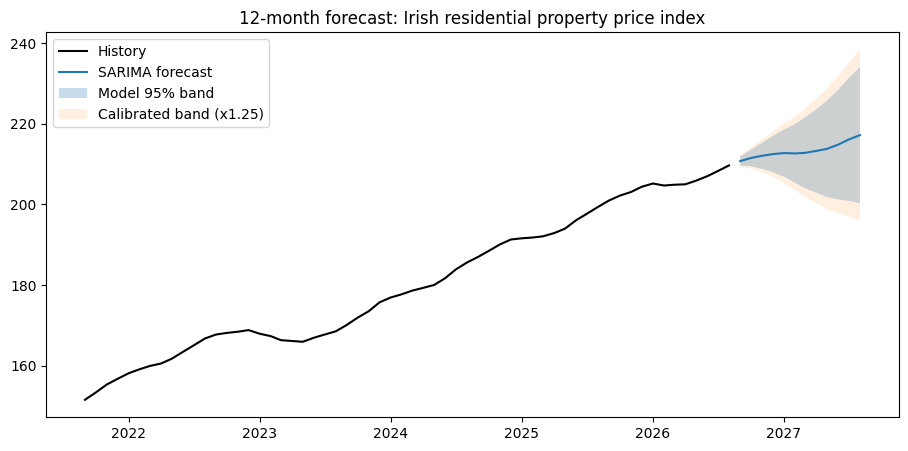

In [27]:
store = []
for w in range(8, 0, -1):
    cut = len(ts) - w * 12
    tr, te = ts.iloc[:cut], ts.iloc[cut:cut + 12]
    m = fit_best_sarima(tr)
    fc = m.get_forecast(12)
    ci = fc.conf_int(alpha=0.05).values
    mean = pd.Series(fc.predicted_mean.values, index=te.index)
    half = pd.Series((ci[:, 1] - ci[:, 0]) / 2, index=te.index)
    store.append((te, mean, half))

def coverage(mult):
    hits = [((te - mean).abs() <= half * mult) for te, mean, half in store]
    return pd.concat(hits).mean()

grid = [1.0, 1.25, 1.5, 1.75, 2.0, 2.5, 3.0, 3.5, 4.0]
table = pd.DataFrame({"band multiplier": grid,
                      "coverage %": [round(coverage(g) * 100, 1) for g in grid]})
display(table)

target = 0.90
mult = next((g for g in grid if coverage(g) >= target), grid[-1])
print("Chosen multiplier:", mult)

final = fit_best_sarima(ts)
fc = final.get_forecast(12)
ci = fc.conf_int(alpha=0.05).values
idx = pd.date_range(ts.index[-1] + pd.offsets.MonthBegin(1), periods=12, freq="MS")
mean = fc.predicted_mean.values
half = (ci[:, 1] - ci[:, 0]) / 2

out = pd.DataFrame({
    "forecast": mean,
    "lower_model": mean - half, "upper_model": mean + half,
    "lower_calibrated": mean - half * mult, "upper_calibrated": mean + half * mult,
}, index=idx).round(2)
display(out)

# 4) Plot
plt.figure(figsize=(11, 5))
plt.plot(ts[-60:], color="black", label="History")
plt.plot(out["forecast"], color="tab:blue", label="SARIMA forecast")
plt.fill_between(out.index, out["lower_model"], out["upper_model"],
                 alpha=0.25, label="Model 95% band")
plt.fill_between(out.index, out["lower_calibrated"], out["upper_calibrated"],
                 alpha=0.12, label=f"Calibrated band (x{mult})")
plt.legend(); plt.title("12-month forecast: Irish residential property price index")
plt.show()


In [28]:
import os, shutil
from google.colab import files

os.makedirs("data", exist_ok=True)

ts.to_csv("data/rppi_clean.csv")
out.to_csv("data/forecast.csv")
mape_by_fold.to_csv("data/mape_by_window.csv")
res.to_csv("data/sarima_nested_windows.csv")

shutil.make_archive("data", "zip", "data")
files.download("data.zip")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>